# 02 — Apriori (association rules)

Category co-occurrence from paid orders + favorites per user.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from corevent_analytics.config import get_settings
from corevent_analytics.data import load_data, build_category_transactions
from corevent_analytics.models import run_apriori

sns.set_theme(style="whitegrid")
settings = get_settings()
tables, source = load_data(settings)
transactions = build_category_transactions(tables)
result = run_apriori(
    transactions,
    min_support=settings.min_support,
    min_confidence=settings.min_confidence,
)
print("source:", source, "| transactions:", result["n_transactions"])
result["frequent_itemsets"].head(20)

source: postgres | transactions: 55


,support,itemsets
0,0.290909,frozenset({music})
1,0.236364,frozenset({sports})
2,0.309091,frozenset({tech})
3,0.290909,frozenset({business})
4,0.272727,frozenset({education})
5,0.309091,frozenset({art_culture})
6,0.290909,frozenset({gastronomy})
7,0.254545,frozenset({health_wellness})
8,0.127273,frozenset({family_kids})
9,0.254545,frozenset({games})


In [2]:
rules = result["rules"]
rules.head(20)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,family_kids,"sports, tech",0.127273,0.054545,0.054545,0.428571,7.857143,1.0,0.047603,1.654545,1.000000,0.428571,0.395604,0.714286
1,fashion_beauty,"business, health_wellness",0.127273,0.054545,0.054545,0.428571,7.857143,1.0,0.047603,1.654545,1.000000,0.428571,0.395604,0.714286
2,"sports, tech",family_kids,0.054545,0.127273,0.054545,1.000000,7.857143,1.0,0.047603,inf,0.923077,0.428571,1.000000,0.714286
3,"business, health_wellness",fashion_beauty,0.054545,0.127273,0.054545,1.000000,7.857143,1.0,0.047603,inf,0.923077,0.428571,1.000000,0.714286
4,"family_kids, tech",sports,0.054545,0.236364,0.054545,1.000000,4.230769,1.0,0.041653,inf,0.807692,0.230769,1.000000,0.615385
5,"art_culture, education",community_social,0.054545,0.236364,0.054545,1.000000,4.230769,1.0,0.041653,inf,0.807692,0.230769,1.000000,0.615385
6,"music, tech",health_wellness,0.054545,0.254545,0.054545,1.000000,3.928571,1.0,0.040661,inf,0.788462,0.214286,1.000000,0.607143
7,"education, music",games,0.054545,0.254545,0.054545,1.000000,3.928571,1.0,0.040661,inf,0.788462,0.214286,1.000000,0.607143
8,"business, gastronomy",games,0.054545,0.254545,0.054545,1.000000,3.928571,1.0,0.040661,inf,0.788462,0.214286,1.000000,0.607143
9,"business, fashion_beauty",health_wellness,0.054545,0.254545,0.054545,1.000000,3.928571,1.0,0.040661,inf,0.788462,0.214286,1.000000,0.607143


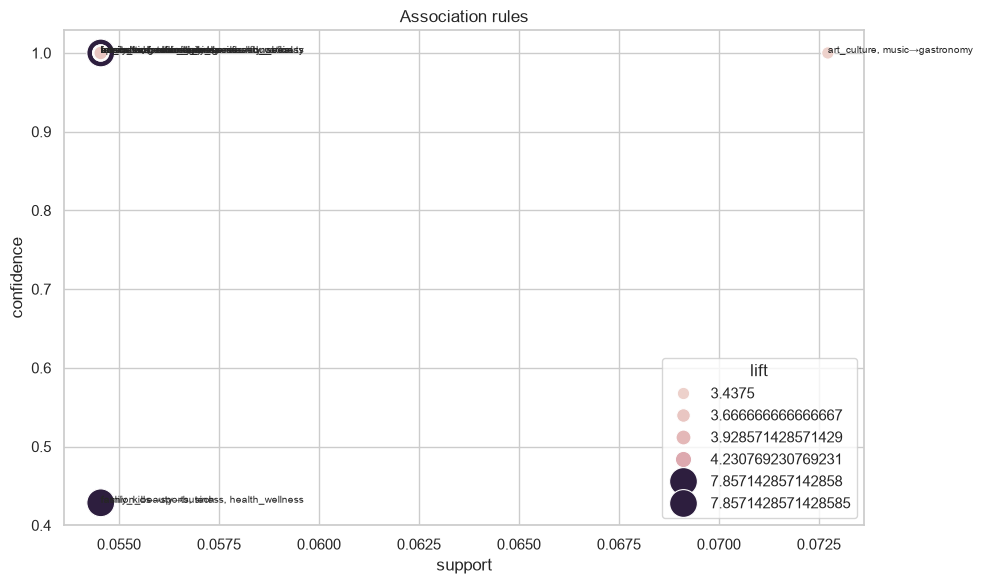

In [3]:
if rules.empty:
    print("No rules — try lowering MIN_SUPPORT / MIN_CONFIDENCE")
else:
    top = rules.head(12)
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.scatterplot(
        data=top,
        x="support",
        y="confidence",
        size="lift",
        hue="lift",
        sizes=(80, 400),
        ax=ax,
    )
    for _, row in top.iterrows():
        ax.text(row["support"], row["confidence"], f"{row['antecedents']}→{row['consequents']}", fontsize=7)
    ax.set_title("Association rules")
    fig.tight_layout()
    plt.show()